# 5.0 Jacobians, Numerical IK, Singularities and Static Torque on the OMX

**ELEC3901 Robotic Manipulators, Lab 5** (week 5: Differential Kinematics: the Jacobian and Numerical Inverse Kinematics)

<br>

Read before this lab: the week 5 lecture and RVC3 Ch. 8.1 to 8.3; Ch. 7.3 (numerical). Each section below follows the lecture slides listed next to it.

### Contents

| Section | Where | Time | Lecture slides |
|---|---|---|---|
| [5.1 Velocity in the plane](#plane) | desk | 8 min | 5-8: Velocity kinematics: the Jacobian; A 2R arm: differentiate the FK; The Jacobian and its columns (here on the OMX's plane) |
| [5.2 Revolute columns, world and tool frames](#columns) | desk | 12 min | 15-19: Columns from the geometry; The rule on the 2R arm; The OMX's joint axes, one column; The OMX's Jacobian; World frame or tool frame |
| [5.3 Singularities and the Newton step](#sing) | desk | 12 min | 9-10, 20, 22, 24: What det J measures; Singularities; The OMX's singularities; Numerical IK: the Newton step; Damped least squares, and masks |
| [5.4 Manipulability](#manip) | desk | 7 min | 11: The manipulability ellipse |
| [5.5 Statics: joint torques from a wrench](#statics) | desk | 8 min | 12-14, 21: Joint torque: a mass on one link; Statics: τ = Jᵀf; J and Jᵀ: motion one way, force the other; On the OMX: a load in the gripper |
| [5.6 On the arm: numerical IK](#newton) | arm | 10 min | 22-23: Numerical IK: the Newton step; Seeds and out of reach |
| [5.7 On the arm: the Jacobian moves the tool](#steps) | arm | 10 min | 5-8: the Jacobian as a linearisation of FK |
| [5.8 On the arm: out to the elbow singularity](#line) | arm | 10 min | 20: The OMX's singularities; 27: Practical: Lab 5 |
| [5.9 The whole lab with the toolbox](#tb) | desk | 5 min | 24-25: Damped least squares, and masks; The Robotics Toolbox in practice |

**How this notebook works.** Each section gives the maths from the lecture, a worked case in code, then the next case for you to
write: a *Task* (a function, checked against hidden values) or an *Exercise* (a few lines with `...` blanks, checked against the
toolbox by `try_it`, which prints `OK` or what looks wrong). Each section ends with the same result from `spatialmath`, the way you
will usually do it. *Desk* sections need no arm: do them before the session if you can. Anything marked **(Optional)** is for
when the core is done: skip it if you are short of time. A **Hint** opens when you click it - try without it first.

*Notation.* The tool's spatial velocity is $\boldsymbol{\nu} = (\mathbf{v}, \boldsymbol{\omega})$: the velocity of the tool point
and the angular velocity, six numbers. The Jacobian $\mathbf{J}(q)$ maps joint rates to it, $\boldsymbol{\nu} = \mathbf{J}(q)\,\dot{q}$;
${}^{0}\mathbf{J}$ (`omx.jacob0`) gives $\boldsymbol{\nu}$ in the base frame {B}, ${}^{E}\mathbf{J}$ (`omx.jacobe`) in the tool frame {E}.
Positive pitch is **nose down**, as on the arm. Lengths in the text are millimetres; the code works in metres, radians and newtons.
Equations are numbered (1), (2), ... through the notebook; the code comments refer to them.

**Checkpoint for sign-off:** The printed checkpoint line: your Jacobian vs the toolbox's, numerical IK on the arm for both elbows (FK of the servo readings), the error of a 40 mm Jacobian step, and where the line to the elbow singularity ended

Reference versions of previous weeks' tasks are imported from `omx_ref.py`, so last week never blocks this week; the functions you
write here are the ones your assignment will be built from.

> **Safety.** Keep the workspace clear of hands and cables before enabling torque, and set a conservative profile velocity
> (`arm.set_profile(60, 20)` or lower) before commanding motion. If anything unexpected happens, press the power isolator on the
> bench first, then think. Torque off (`arm.torque(False)`) before touching the arm.

The imports for this notebook. Section 5.6 connects to the arm; nothing before it needs the arm. This lab does not use the camera.

In [ ]:
import sys, os
# Repository layout: weekNN/ (notebooks), scripts/ (helper modules), data/ (your measurements, shared by every week).
for _up in ('.', '..', os.path.join('..', '..')):
    if os.path.isdir(os.path.join(_up, 'scripts')):
        _root = os.path.abspath(_up); sys.path.insert(0, os.path.join(_root, 'scripts'))
        os.makedirs(os.path.join(_root, 'data'), exist_ok=True); os.chdir(os.path.join(_root, 'data'))   # files save/load here
        break
import numpy as np, matplotlib.pyplot as plt, time, cv2
import roboticstoolbox as rtb
from spatialmath import SE3, SO3, SE2, UnitQuaternion
from spatialmath.base import trplot, tranimate
from omx_model import omx_robot, omx_ik, Q_LIM, T_EC, P_TIP_E, mount_tilt, look_down_pitch
from omx import OMX
from omx_camera import Camera, tip_in_mat, predicted_T_CM, pose_error
from omx_calib import small_T
from labcheck import check, try_it
NOM = dict(d1=0.0975, l2z=0.11315, l2x=0.0415, l3=0.162, l4=0.123)   # nominal link parameters (m)
from omx_ref import R_to_rpy, camera_ik, chain_T_BM, dh_table, error_stats, fk_dh, inv_T, make_T, mount_from_views, omx_fk, omx_ik, planar_2r, plot_error_field, rot2, rot_about, rotx, roty, rotz, rpy_to_R, se2, step_log, transform_point, transform_points, transl2, trot2   # reference versions of PREVIOUS labs' tasks; your own definitions below override them
np.set_printoptions(precision=4, suppress=True)
%matplotlib inline
omx = omx_robot()              # Robotics Toolbox model (nominal)
T_EC_CAD = T_EC   # the design camera mount (ROBOTIS CAD: optical axis 38 deg below the tool). Each arm's camera sits a little differently: Lab 2
                  # measures yours, and from Lab 3 on the MOUNT cell re-measures it every session and replaces T_EC
HOVER = 0.09      # tip hover height with the tool vertical: the OMX-F reaches r ~ 0.24 m there (touching the mat: r ~ 0.28 m)
CAM_HOVER = 0.15  # tip height for camera measurements, tool pitched with look_down_pitch(T_EC) so the camera looks straight down:
                  # the camera is then ~180 mm up, enough to see the marker ring around the clear zone

In [ ]:
from omx import STALL_TORQUE                          # 1.4 N m (XL430, joints 1-3), 0.52 N m (XL330, joint 4)
d1 = NOM['d1']
l2z = NOM['l2z']
l2x = NOM['l2x']
l3 = NOM['l3']
l4 = NOM['l4']
a2 = np.hypot(l2x, l2z)                              # Lab 3, equation (1): link 2 as one straight line
beta = np.arctan2(l2x, l2z)
g = 9.81
q_home = np.radians([0, -60, 60, 30])

<br>

<a id='plane'></a>

### 5.1 Velocity in the plane (desk)
---

Forward kinematics gives the tool's pose; this week asks how fast it moves when the joints turn. Start where Lab 3 started: in the
vertical plane of the arm, joints 2, 3 and 4 set the tip's reach $r$, its height $z$ and the tool pitch $\theta$:

$$ r = a_2\sin(q_2+\beta) + l_3\cos(q_2+q_3) + l_4\cos\theta, \qquad
   z = d_1 + a_2\cos(q_2+\beta) - l_3\sin(q_2+q_3) - l_4\sin\theta, \qquad \theta = q_2+q_3+q_4 \qquad (1) $$

Differentiate with respect to time, one term at a time (the chain rule: $\frac{d}{dt}\sin u = \cos u\,\dot{u}$):

$$ \dot{r} = a_2\cos(q_2+\beta)\,\dot{q}_2 - l_3\sin(q_2+q_3)\,(\dot{q}_2+\dot{q}_3) - l_4\sin\theta\,\dot{\theta}, \qquad
   \dot{z} = -a_2\sin(q_2+\beta)\,\dot{q}_2 - l_3\cos(q_2+q_3)\,(\dot{q}_2+\dot{q}_3) - l_4\cos\theta\,\dot{\theta} \qquad (2) $$

with $\dot\theta = \dot{q}_2 + \dot{q}_3 + \dot{q}_4$. Every term is linear in the joint rates, so collect them into a matrix:

$$ \begin{bmatrix} \dot{r} \\ \dot{z} \\ \dot{\theta} \end{bmatrix} = \mathbf{J}_p(q)
   \begin{bmatrix} \dot{q}_2 \\ \dot{q}_3 \\ \dot{q}_4 \end{bmatrix} \qquad (3) $$

Column $i$ of $\mathbf{J}_p$ is the tip's velocity when joint $i$ alone turns at 1 rad/s. Joint 4 only appears through $\theta$, so its
column is the simplest: $(-l_4\sin\theta,\; -l_4\cos\theta,\; 1)$.

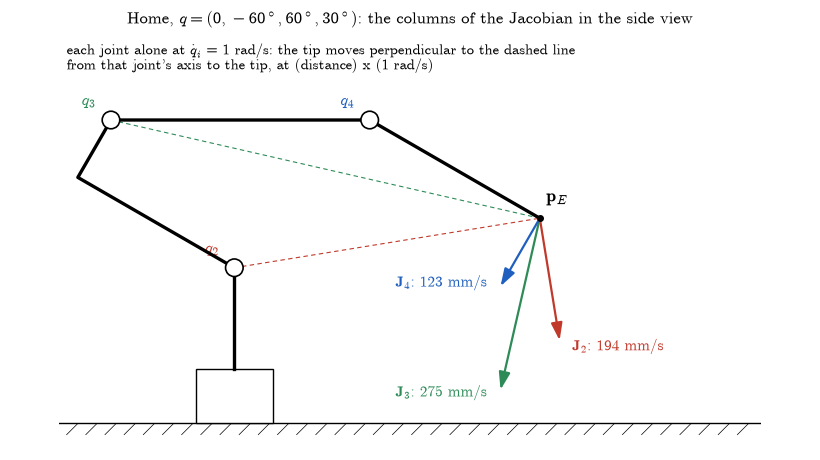

*The columns at home. Each joint alone at 1 rad/s moves the tip perpendicular to the line from its axis to
    the tip, at a speed equal to that distance: joint 3 is furthest from the tip and moves it fastest.*

In [ ]:
# --- worked case: column 4 of J_p at home, equations (2) and (3) ---------------------------------------------------------
q1, q2, q3, q4 = q_home
th = q2 + q3 + q4
col4 = np.array([-l4 * np.sin(th), -l4 * np.cos(th), 1.0])           # (r_dot, z_dot, theta_dot) for q4_dot = 1 rad/s
speed = np.hypot(col4[0], col4[1])                                   # the tip's speed in the plane
print('column 4 at home:', np.round(col4, 4), '  speed of the tip:', round(1e3 * speed), 'mm/s = l4 x 1 rad/s')

**Your turn: columns 2 and 3.** Read them off equation (2): the coefficient of $\dot{q}_2$, then of $\dot{q}_3$. At $q_1 = 0$ the plane
is the x-z plane, so $\dot{r} = \dot{x}$ and the pitch rate is $\omega_y$: the check takes rows x, z and $\omega_y$ of the toolbox's
${}^{0}\mathbf{J}$.

In [ ]:
# --- Exercise 5.1a: the plane Jacobian J_p at home ------------------------------------------------------------------
col2 = ...                         # (r_dot, z_dot, theta_dot) for q2_dot = 1 rad/s, equation (2)
col3 = ...                         # the same for q3_dot = 1 rad/s
try_it('columns 2, 3, 4 of J_p at home', [col2, col3, col4], omx.jacob0(q_home)[[0, 2, 4]][:, 1:].T);

<details><summary><b>Hint</b></summary>

$\dot{q}_2$ appears in all three terms of $\dot{r}$ (through $q_2+\beta$, $q_2+q_3$ and $\theta$); $\dot{q}_3$ only in the last two.
Every column has a 1 in the $\dot\theta$ row: each pitch joint turns the tool at its own rate.

</details>

<br>

<a id='columns'></a>

### 5.2 Revolute columns, world and tool frames (desk)
---

The figure in 5.1 already showed the rule. A revolute joint $i$ with unit axis $\hat{\mathbf{z}}_i$ through the point $\mathbf{p}_i$ moves the tool
point like a wheel: at velocity $\hat{\mathbf{z}}_i \times (\mathbf{p}_E - \mathbf{p}_i)$, and turns the tool at angular velocity
$\hat{\mathbf{z}}_i$, both per unit joint rate. So column $i$ of the full 6 x 4 Jacobian is

$$ \mathbf{J}_i = \begin{bmatrix} \hat{\mathbf{z}}_i \times (\mathbf{p}_E - \mathbf{p}_i) \\ \hat{\mathbf{z}}_i \end{bmatrix}
   \qquad (4) $$

No derivatives at all: only where each axis is and which way it points. On the OMX, joint 1 turns about the vertical $\hat{\mathbf{z}}_B$
through the origin. Joints 2, 3 and 4 all turn about the same horizontal direction $\hat{\mathbf{y}}_1 = \mathbf{R}_z(q_1)\,\hat{\mathbf{y}}$,
through the shoulder, the elbow and the wrist.

In [ ]:
# --- worked case: column 1 from equation (4) -------------------------------------------------------------------------
q = np.array([0.3, 0.5, -0.2, 0.4])
p_E = omx.fkine(q).t
z_1 = np.array([0, 0, 1.0])                                     # the joint-1 axis: vertical,
p_1 = np.zeros(3)                                               # through the base origin
J_1 = np.r_[np.cross(z_1, p_E - p_1), z_1]
print('column 1 = (-y, x, 0, 0, 0, 1):', np.round(J_1, 4))
try_it('column 1', J_1, omx.jacob0(q)[:, 0]);

**Your turn: the whole Jacobian.** Write Task 1 with equation (4): the points on the pitch axes come from the ETS (Lab 3,
equation (4)); the common axis direction is $\hat{\mathbf{y}}$ turned by $q_1$.

### Task 1 — The Jacobian from the joint axes
Write `revolute_jacobian(q, p=NOM)` returning the OMX's 6 x 4 Jacobian in the base frame, column by column from equation (4):
column i is (z_i x (p_E - p_i), z_i), with z_i the joint's axis and p_i a point on it. Joint 1 turns about the vertical through the
origin; joints 2-4 about y turned by q1, through the shoulder, the elbow and the wrist (the ETS of Lab 3). Compare with `omx.jacob0(q)`.

In [ ]:
def revolute_jacobian(q, p=NOM):
    """6x4 Jacobian (v; w) of the OMX tool point in the base frame: column i = (z_i x (p_E - p_i), z_i)."""
    # TODO: write your implementation here, one step under each comment

    # where the tool point is (Lab 3's FK)

    # joint 1: the vertical axis through the origin

    # joints 2-4: the same horizontal axis, y turned by q1

    # a point on each pitch axis, along the ETS of Lab 3: the shoulder (height d1), then the elbow (link 2 turned by q1 and q2),
    # then the wrist (link 3 turned by q1, q2 and q3)

    # one column per joint: list the four axes and the four points, then loop over them into a 6 x 4 array

    # equation (4): the velocity part, then the angular part

    raise NotImplementedError   # delete this line when your code is complete


In [ ]:
# --- self-check (hidden expected values) ---------------------------------------------------------
check('J at (0.3, 0.5, -0.2, 0.4)', lambda: revolute_jacobian(np.array([0.3, 0.5, -0.2, 0.4])), '8ea682862c', decimals=3)
check('column 1 at q = 0 is along +y', lambda: revolute_jacobian(np.zeros(4))[:, 0], 'a070d1ad99', decimals=3);

<details><summary><b>Hint</b></summary>

The points: the shoulder `p_2 = (0, 0, d1)`; the elbow `p_3 = p_2 + Rz(q1) Ry(q2) (l2x, 0, l2z)`; the wrist
`p_4 = p_3 + Rz(q1) Ry(q2) Ry(q3) (l3, 0, 0)`, with `rotz` and `roty` from Lab 3. Then loop over the joints:
`J[:3, i] = np.cross(axis, p_E - point)` and `J[3:, i] = axis`.

</details>

**With the toolbox.** `omx.jacob0(q)` computes the same matrix from the ETS.

In [ ]:
for qt in (q, np.zeros(4), q_home):
    try_it(f'revolute_jacobian at q = {np.round(qt, 3)}', lambda: revolute_jacobian(qt), omx.jacob0(qt), tol=1e-6)
y_1 = SO3.Rz(q[0]).A[:, 1]                                        # the common pitch-axis direction, used below

**World or tool frame.** ${}^{0}\mathbf{J}$ gives the velocity in {B}. The same velocity written in the tool frame {E} needs the rotation
${}^{B}\mathbf{R}_{E}$ of the tool, applied to both halves:

$$ {}^{E}\mathbf{J} = \begin{bmatrix} {}^{B}\mathbf{R}_{E}^{T} & \mathbf{0} \\ \mathbf{0} & {}^{B}\mathbf{R}_{E}^{T} \end{bmatrix}
   {}^{0}\mathbf{J} \qquad (5) $$

The tool frame suits the OMX: whatever $q_1$ is, the pitch rate is $\omega_y$ in {E}. The four directions the arm controls are the tool
point's velocity and the pitch rate. Those are rows $(v_x, v_y, v_z, \omega_y)$ of ${}^{E}\mathbf{J}$, a 4 x 4 matrix: the
**task Jacobian** $\mathbf{J}_{task}$.

**Six rows, four joints.** The angular part is $\boldsymbol{\omega} = \dot{q}_1\,\hat{\mathbf{z}}_B + (\dot{q}_2+\dot{q}_3+\dot{q}_4)\,\hat{\mathbf{y}}_1$:
only two directions, so there is one axis the tool can never turn about. Find it, then write ${}^{E}\mathbf{J}$ with equation (5).

In [ ]:
# --- Exercise 5.2b: the rotation the OMX can never make, and the tool-frame Jacobian (5) ----------------------------
rank_J = ...                       # the rank of B_J at q (np.linalg.matrix_rank)
never = ...                        # a unit vector (3,), in {B}: the axis the tool can never rotate about at q
J0 = omx.jacob0(q)                                                # B_J
R = omx.fkine(q).R                                                # B_R_E
Je_mine = ...                      # equation (5): R^T times the top three rows of J0, stacked on R^T times the bottom three
U, S, Vt = np.linalg.svd(J0[3:])                                  # the angular rows: the last left singular vector is missed
try_it('rank of B_J', rank_J, 4)
try_it('|never . (missed direction)|', lambda: abs(np.dot(never, U[:, -1])), 1.0)
try_it('E_J at q', Je_mine, omx.jacobe(q));

In [ ]:
# the task Jacobian, used from here on; and why the tool frame
MASK = np.array([1, 1, 1, 0, 1, 0], dtype=bool)
def J_task(q):
    return omx.jacobe(q)[MASK]                                    # rows (vx, vy, vz, wy) in {E}: 4 x 4
q_turned = np.array([0.8, 0.3, 0.4, 0.2])
print('pitch-rate row, base frame (w_y of B_J):', np.round(omx.jacob0(q_turned)[4], 3), ' - depends on q1')
print('pitch-rate row, tool frame (w_y of E_J):', np.round(omx.jacobe(q_turned)[4], 3), ' - 1 for each pitch joint')

<br>

<a id='sing'></a>

### 5.3 Singularities and the Newton step (desk)
---

A pose is **singular** when some tool motion can no longer be made, whatever the joint rates. For a square Jacobian that happens
where its determinant is zero, $\det \mathbf{J}_{task} = 0$ (lecture slides 9 and 10). For the OMX the determinant works out as
the reach $r$ (the tip's distance from the joint-1 axis) times a term for the elbow:

$$ |\det \mathbf{J}_{task}| = |r|\; a_2\, l_3\, |\cos(q_3 - \beta)| \qquad (6) $$

Two singularities, with physical meanings:

* **the elbow straight**, $q_3 = \beta - 90^\circ$: link 3 continues the shoulder-elbow line, and the tip cannot move along the arm;
* **the tip over the base**, $r = 0$ (the lecture's wrist-over-base singularity, for the tool point): joint 1 only spins the tool
  about its own position, and no joint moves it sideways.

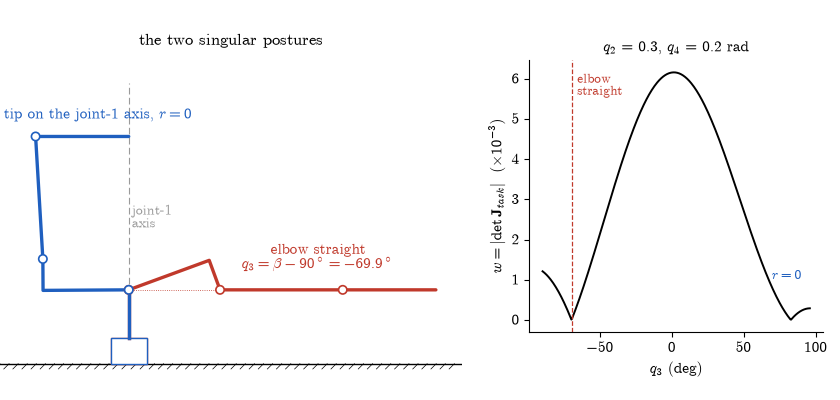

*Left: the two singular postures. Right: |det J_task| along a sweep of q3 (q2 = 0.3, q4 = 0.2 rad): zero with the
    elbow straight, and again near q3 = 82 degrees, where this sweep carries the tip across the joint-1 axis.*

In [ ]:
# --- worked case: sweep q3, find where det J_task vanishes -----------------------------------------------------------------
q3s = np.linspace(Q_LIM[2, 0], Q_LIM[2, 1], 2001)
dets = []
for a in q3s:
    q_a = np.array([0, 0.3, a, 0.2])
    dets.append(np.linalg.det(J_task(q_a)))
dets = np.array(dets)
plt.figure(figsize=(6, 3))
plt.plot(np.degrees(q3s), np.abs(dets))
plt.xlabel('q3 (deg)')
plt.ylabel('|det J_task|')
plt.show()
k = np.argmin(np.abs(dets[q3s < 0]))                              # the zero with the elbow bent up (q3 < 0)
print(f'the first zero of the sweep: q3 = {np.degrees(q3s[k]):.2f} deg')

In [ ]:
# --- Exercise 5.3a: predict the elbow singularity -------------------------------------------------------------------
my_guess = ...                     # q3 (deg) with the elbow straight, from the geometry (beta is defined above)
try_it('elbow-straight q3 (deg)', my_guess, np.degrees(q3s[k]), tol=0.2);

**Your turn: equation (6) as code.** Check it against the toolbox at random poses inside the joint limits.

In [ ]:
# --- Exercise 5.3b: the determinant in closed form ------------------------------------------------------------------
def det_closed(q):
    r = ...                        # the tip's distance from the joint-1 axis, omx.fkine(q).t
    return ...                     # equation (6)

Qr = np.random.default_rng(4).uniform(Q_LIM[:, 0], Q_LIM[:, 1], size=(6, 4))
try_it('|det J_task| at 6 random poses', lambda: [det_closed(qr) for qr in Qr], [abs(np.linalg.det(J_task(qr))) for qr in Qr], tol=1e-9);

**Why singularities matter: numerical IK.** The Jacobian's first use is inverse kinematics without a closed form. Start from a guess
(the *seed*) $q$ and improve it. The task is four numbers in {B}, $\mathbf{x} = \mathbf{f}(q) = (x, y, z, \theta)$ with
$\theta = q_2 + q_3 + q_4$; its 4 x 4 Jacobian is $\mathbf{J}_v$ (your Task 1) with the pitch row $(0, 1, 1, 1)$ underneath. Near $q$,
$\mathbf{f}(q + \Delta q) \approx \mathbf{f}(q) + \mathbf{J}\,\Delta q$: ask for the error to vanish, the **Newton step**,

$$ \mathbf{e} = \mathbf{x}^{*} - \mathbf{f}(q), \qquad \mathbf{J}\,\Delta q = \mathbf{e}, \qquad q \leftarrow q + \Delta q \qquad (7) $$

and repeat. At a singularity $\mathbf{J}$ has no inverse, and (7) asks for an infinite step. The fix is to add a small number
$\lambda$ to the diagonal before solving. Then the matrix always has an inverse and the step stays a sensible size, at the cost of a
slightly less accurate step each time. This is the **damped step** (also called damped least squares):

$$ \Delta q = \left(\mathbf{J}^{T}\mathbf{J} + \lambda\,\mathbf{I}\right)^{-1}\mathbf{J}^{T}\,\mathbf{e} \qquad (8) $$

The target is the lecture's: the tip at $\mathbf{p}^{*}$ = (360, 0, 260) mm with the tool pitched 40 degrees up.

In [ ]:
# --- worked case: Newton, equation (7), from home towards p* = (0.36, 0, 0.26) m, pitch -40 deg (tool up) ---------------
p_star = np.array([0.36, 0.0, 0.26])
th_star = np.radians(-40)
x_star = np.append(p_star, th_star)

def task(q):
    # f(q) = (x, y, z, theta) in {B}
    p = omx.fkine(q).t
    theta = q[1] + q[2] + q[3]
    return np.append(p, theta)

def J_newton(q):
    # the 4 x 4 task Jacobian: the toolbox's J_v (your revolute_jacobian gives the same rows) over the pitch row
    Jv = omx.jacob0(q)[:3]
    return np.vstack([Jv, [0, 1, 1, 1]])

q = q_home.copy()
for k in range(7):
    e = x_star - task(q)                                          # equation (7): the error
    print(f'step {k}: |e| = {np.linalg.norm(e):.1e}   q = {np.round(np.degrees(q), 2)} deg')
    dq = np.linalg.solve(J_newton(q), e)                          # equation (7): the step
    q = q + dq
print('analytic, elbow up (omx_ik):', np.round(np.degrees(omx_ik(p_star, th_star, 'up')), 2), 'deg')
print('far from the answer the steps are rough; close to it the error is roughly squared at each step')

**Your turn: a step at the singularity.** With the elbow straight ($q_3 = \beta - 90°$) the arm cannot move its wrist along link 3,
and $\mathbf{J}$ is singular: equation (7) fails there. Take the damped step (8) instead.

In [ ]:
# --- Exercise 5.3c: the damped step at the singular seed ---------------------------------------------------------------
q_sing = np.array([0.0, 0.0, beta - np.pi / 2, 0.0])                       # elbow straight
lam = 0.01
e_s = ...                          # the task error at q_sing (4,), equation (7)
J_s = ...                          # the task Jacobian at q_sing (4 x 4): J_newton
dq_dls = ...                       # equation (8)
U, S, Vt = np.linalg.svd(np.vstack([omx.jacob0(q_sing)[:3], [0, 1, 1, 1]]))
e_ref = x_star - np.append(omx.fkine(q_sing).t, q_sing[1] + q_sing[2] + q_sing[3])
try_it('damped step (rad)', dq_dls, Vt.T @ np.diag(S / (S ** 2 + lam)) @ U.T @ e_ref)   # (8), computed another way (through the SVD);

<details><summary><b>Hint</b></summary>

`e_s = x_star - task(q_sing)` and `J_s = J_newton(q_sing)`; then `np.linalg.solve(J_s.T @ J_s + lam * np.eye(4), J_s.T @ e_s)`.

</details>

<br>

<a id='manip'></a>

### 5.4 Manipulability (desk)
---

Near a singularity the arm is slow in some directions. Send every joint-rate vector of length one, $\|\dot{q}\| = 1$, through the
Jacobian: the tool velocities fill an **ellipse** (an ellipsoid in 3-D), as on lecture slide 11. Its half-widths are the singular
values $\sigma_1 \ge \sigma_2 \ge \dots$ of $\mathbf{J}$ (`np.linalg.svd`); Exercise 5.4a finds them another way, from
$\mathbf{J}\mathbf{J}^T$. The ellipse's area (volume) is Yoshikawa's measure of manipulability:

$$ w = \sqrt{\det\left(\mathbf{J}\,\mathbf{J}^{T}\right)} = \sigma_1 \sigma_2 \cdots \qquad (9) $$

For a square $\mathbf{J}$, $w = |\det \mathbf{J}|$: equation (6) is the OMX's manipulability. $w = 0$ at a singularity; larger is
better. Its units depend on the rows you keep, so compare $w$ only between poses, never between different Jacobians.

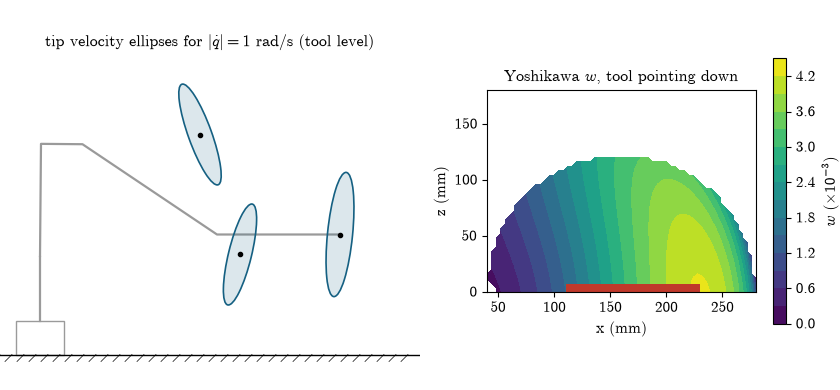

*Left: the tip's velocity ellipses in the side view (joints 2-4 at unit total rate, tool level), drawn at 0.15 mm
    per mm/s. Near full reach the ellipse flattens to a line across the arm: no speed along it. Right: w = |det J_task| with the tool pointing
    straight down; red: the mat's clear zone.*

In [ ]:
# --- worked case: the velocity ellipse of the tip at home, in the side view ---------------------------------------------
J_xz = omx.jacob0(q_home)[[0, 2]][:, 1:]                          # tip (x, z) velocity from (q2, q3, q4): 2 x 3
U, S, Vt = np.linalg.svd(J_xz)
t = np.linspace(0, 2 * np.pi, 200)
circle = np.vstack([np.cos(t), np.sin(t)])
E = U @ np.diag(S) @ circle                                       # the unit circle, stretched by S and turned by U
plt.figure(figsize=(4, 4))
plt.plot(1e3 * E[0], 1e3 * E[1])
plt.axis('equal')
plt.grid()
plt.xlabel('x_dot (mm/s)')
plt.ylabel('z_dot (mm/s)')
plt.title('tip velocities at home, |q_dot| = 1 rad/s')
plt.show()
print(f'semi-axes {np.round(1e3 * S, 1)} mm/s, the long one along {np.round(U[:, 0], 2)} (x, z)')

In [ ]:
# --- Exercise 5.4a: the semi-axes from J J^T ------------------------------------------------------------------------
lam = ...                          # the eigenvalues of J_xz @ J_xz.T, largest first (np.linalg.eigvalsh gives them smallest first)
axes_mm = ...                      # the semi-axes in mm/s
try_it('semi-axes (mm/s)', axes_mm, 1e3 * np.linalg.svd(J_xz, compute_uv=False), tol=1e-6);

### Task 2 — Manipulability and conditioning
Write `manipulability(J)` = sqrt(det(J J^T)) and `condition_number(J)` = ratio of largest to smallest singular value, for any
m x n Jacobian with m <= n. Use them in Section 5.4 and to decide where a numerical IK solver will struggle.

In [ ]:
def manipulability(J):
    """Yoshikawa measure sqrt(det(J J^T))."""
    # TODO: write your implementation here, one step under each comment

    # equation (9): the volume of the velocity ellipsoid, sqrt(det(J J^T))

    # at a singularity rounding can make the determinant a tiny negative number: treat that as zero

    raise NotImplementedError   # delete this line when your code is complete

def condition_number(J):
    """sigma_max / sigma_min of J."""
    # TODO: write your implementation here, one step under each comment

    # the singular values of J (np.linalg.svd with compute_uv=False) come largest first

    # the longest semi-axis over the shortest

    raise NotImplementedError   # delete this line when your code is complete


In [ ]:
# --- self-check (hidden expected values) ---------------------------------------------------------
check('manipulability at (0.3, 0.5, -0.2, 0.4)', lambda: manipulability(revolute_jacobian(np.array([0.3, 0.5, -0.2, 0.4]))[:3]), 'a2f8f1110c', decimals=5)
check('condition number at (0.3, 0.5, -0.2, 0.4)', lambda: condition_number(revolute_jacobian(np.array([0.3, 0.5, -0.2, 0.4]))[:3]), 'f8620e9a22', decimals=3)
check('manipulability collapses when the arm is straight', lambda: manipulability(revolute_jacobian(np.array([0.0, np.pi/2 - np.arctan2(0.0415, 0.11315), np.arctan2(0.0415, 0.11315) - np.pi/2, 0.0]))[:3]), '05fe405753', decimals=5);

<details><summary><b>Hint</b></summary>

`np.sqrt(np.linalg.det(J @ J.T))` - guard against a tiny negative determinant from rounding with `max(..., 0.0)`. For the condition
number, `np.linalg.svd(J, compute_uv=False)` returns the singular values largest first.

</details>

The condition number $\sigma_1/\sigma_n$ (also in the Task) is 1 when the ellipsoid is a sphere and grows without bound at a singularity.
**With the toolbox:**

In [ ]:
try_it('manipulability of J_task at q', lambda: manipulability(J_task(q)), abs(np.linalg.det(J_task(q))))
try_it('manipulability of J_v at q', lambda: manipulability(omx.jacob0(q)[:3]), omx.manipulability(q, axes='trans'))
try_it('condition number of J_task at q', lambda: condition_number(J_task(q)), np.linalg.cond(J_task(q)));

**Why Newton stalls near a singularity.** Each Newton step (7) solves $\mathbf{J}\,\Delta q = \mathbf{e}$. Where the condition
number is large, a small error in one direction asks for a huge joint step; at the singular seed of Section 5.3 (the elbow straight)
it is infinite, and only the damping of (8) kept the step finite.

In [ ]:
# --- Exercise 5.4b: the condition number near the singular seed ---------------------------------------------------------
q_near = np.array([0.0, 0.0, beta - np.pi / 2 + np.radians(1), 0.0])   # 1 degree from the elbow straight
kappa = ...                        # [condition number of J_task at q_near, at q_home] (your condition_number)
try_it('condition numbers near the singularity and at home', kappa, [np.linalg.cond(J_task(q_near)), np.linalg.cond(J_task(q_home))]);

By equation (6), $w$ grows with the reach $r$ and with $|\cos(q_3 - \beta)|$: it is largest with the elbow bent at a right angle,
and zero at the edge of the reach, where the elbow straightens. Section 5.8 takes the arm out to that edge.

<br>

<a id='statics'></a>

### 5.5 Statics: joint torques from a wrench (desk)
---

The Jacobian also works backwards, for forces (lecture slides 12 to 14). Let the tool push with a force $\mathbf{f}$ at its tip and
hold still. The joint torques that hold it are

$$ \boldsymbol{\tau} = \mathbf{J}^{T}(q)\,\mathbf{w} \qquad (10) $$

with $\mathbf{w}$ and $\mathbf{J}$ in the same frame. Here $\mathbf{w}$ is the force, plus a twisting moment $\mathbf{m}$ if there is
one (together called a *wrench*). With no moment only the top three rows of $\mathbf{J}$, $\mathbf{J}_v$, matter.

To **hold a mass** $m$ the tool pushes up on it: $\mathbf{f} = (0, 0, +mg)$ in {B}. Compare the torques with what the servos can
give, their stall torques: 1.4 N m for the XL430s (joints 1-3) and 0.52 N m for the XL330 (joint 4).

The worked case is the lecture's example (slides 13 and 21): 100 g held in the gripper, tip 300 mm out and 120 mm up, tool level.

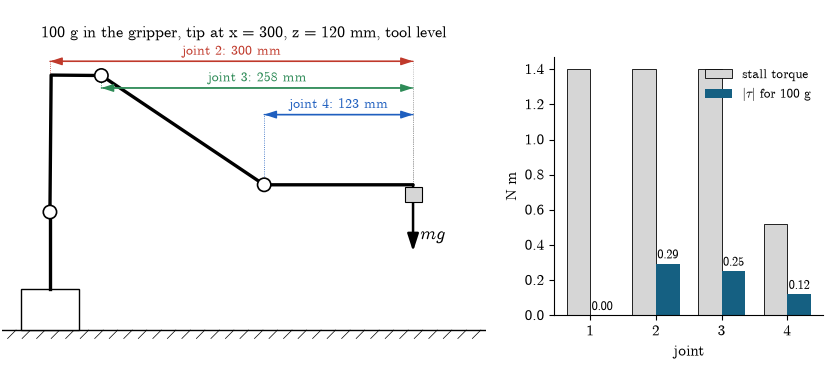

*100 g in the gripper with the tip at x = 300 mm, z = 120 mm, tool level. Each pitch joint's torque is mg times
    its horizontal distance to the tip; joint 1 carries none. The arm's own weight (Lab 7) comes on top.*

In [ ]:
# --- worked case: 100 g at x = 300 mm, z = 120 mm, tool level, equation (10) ---------------------------------------------
m = 0.100
q_s = omx_ik([0.30, 0, 0.12], pitch=0.0)
w = np.array([0, 0, m * g, 0, 0, 0])                              # the tool holding the mass up, in {B}
tau = omx.jacob0(q_s).T @ w
print('tau (N m):', np.round(tau, 3), '  fraction of stall:', np.round(np.abs(tau) / STALL_TORQUE, 2))

### Task 3 — Static joint torques from an end-effector force
Write `static_torque(Jv, force)` returning the joint torques (4,) for the tool to exert the force `force` (3,) at the end effector
(to hold a mass m up, force = (0, 0, +m g)), using the translational Jacobian. Section 5.5 uses it on the lecture's example: 100 g held
in the gripper, tip 300 mm out and 120 mm up, tool level.

In [ ]:
def static_torque(Jv, force):
    """tau = Jv^T f. Jv 3x4, force (3,) N -> tau (4,) N m."""
    # TODO: write your implementation here, one step under each comment

    # make both arrays (the force may come in as a list)

    # equation (10): tau = J^T w, the force part of the wrench only, so the 3 x 4 Jv transposed times f

    raise NotImplementedError   # delete this line when your code is complete


In [ ]:
# --- self-check (hidden expected values) ---------------------------------------------------------
check('tau for 50 g at (0, 0.6, -0.2, 0.3)', lambda: static_torque(revolute_jacobian(np.array([0, 0.6, -0.2, 0.3]))[:3], [0, 0, 0.05 * 9.81]), '4632cb32b4', decimals=5)
check('joint 1 carries no gravity load', lambda: static_torque(revolute_jacobian(np.array([0.7, 0.6, -0.2, 0.3]))[:3], [0, 0, 0.4905])[0], '05fe405753', decimals=6);

**With the toolbox.** `omx.pay(W, q, frame=0)` gives the joint torques for a payload wrench `W` acting **on** the tool (the weight,
$(0, 0, -mg)$): the same torques as equation (10) with the tool's push $+mg$.

In [ ]:
try_it('static_torque for 100 g at q_s', lambda: static_torque(revolute_jacobian(q_s)[:3], [0, 0, m * g]),
       omx.pay([0, 0, -m * g, 0, 0, 0], q_s, frame=0), tol=1e-6);

**Your turn: how much could it hold here?** Equation (10) is linear in the mass. Ignoring the arm's own weight, find the heaviest mass
the arm could hold at `q_s` with every joint within its stall torque, and which joint gives up first.

In [ ]:
# --- Exercise 5.5a: the heaviest mass at q_s ------------------------------------------------------------------------
tau_per_kg = ...                   # |tau| (4,) for 1 kg held at q_s, equation (10)
m_max = ...                        # the largest mass (kg) with |tau| <= STALL_TORQUE for joints 2, 3 and 4 (joint 1 carries none)
# reference: each pitch joint's torque is g x its horizontal distance to the tip
elbow_x = a2 * np.sin(q_s[1] + beta)
wrist_x = elbow_x + l3 * np.cos(q_s[1] + q_s[2])
tip_x = omx.fkine(q_s).t[0]
levers = np.array([tip_x, tip_x - elbow_x, tip_x - wrist_x])
try_it('heaviest mass at q_s (kg)', m_max, np.min(STALL_TORQUE[1:] / (g * levers)));

**Forces at a singularity.** The arm straight out and level, $q = (0,\; 90^\circ - \beta,\; \beta - 90^\circ,\; 0)$, is the elbow
singularity: the tip cannot move along the arm. Now push the tip *along* the arm with 1 N. Predict the joint torques first.

In [ ]:
# --- Exercise 5.5b: a push along the arm at the singularity ---------------------------------------------------------
q_str = np.array([0, np.pi / 2 - beta, beta - np.pi / 2, 0])     # straight out and level
my_guess = ...                     # tau (4,) in N m, before computing anything
tau_push = ...                     # equation (10) for f = (1, 0, 0) N at q_str
try_it('your prediction', my_guess, omx.jacob0(q_str)[:3].T @ [1.0, 0, 0], tol=1e-6)
try_it('tau for a push along the arm', tau_push, np.zeros(4), tol=1e-6);

The direction the arm cannot move in is exactly the direction it can resist for free: the structure carries the force, not the
motors. A force the arm cannot move along needs no motor torque.

<br>

<a id='newton'></a>

### 5.6 On the arm: numerical IK (arm)
---

From here on you need the arm, or the digital twin (`SIMULATE = True` in the next cell).

In [ ]:
# --- connect to the arm --------------------------------------------------------------------------------------------
# Safe to re-run: an existing connection is closed first, so the COM port is released before it is opened again.
# SIMULATE = True runs the MuJoCo digital twin (omx_mujoco.py) instead of the real arm: same API, a rendered
# wrist camera, and optional hidden model errors so you can test calibration against ground truth.
SIMULATE = False
PORT = 'auto'                  # finds the OpenRB-150 by its USB id; or set it, e.g. 'COM4' (Device Manager) / '/dev/ttyACM0'
# --- which arm are you on today? Read the asset label on the base. Everything you measure is tagged with it,
#     because zero offsets, camera intrinsics and the camera mount are all properties of THIS arm.
ARM_ID = 'OMX-00'            # EDIT every session
if 'arm' in globals():
    try:
        arm.close()
    except Exception as e:
        print('closing the previous connection:', e)
    del arm
if SIMULATE:
    from omx_mujoco import OMXSim, SimCamera
    arm = OMXSim(view=True)    # view=False if no display; set kin_error=..., joint_offsets=... to hide errors
    # Video: arm.record('run.mp4') writes the wrist camera and a scene camera side by side (same size) while the arm
    # moves; arm.stop_recording() when done.
else:
    arm = OMX(PORT)
print('connected:', 'digital twin' if SIMULATE else arm.port_name, '| arm', ARM_ID)

**The solver.** Repeat the damped step (8) until the error is small, or stop after `iters` steps. This is `newton_ik` below, given:
the toolbox's `ikine_LM` without its restarts and joint-limit checks. On the arm, the seed is where the arm is now - its servo
readings - and the target is Section 5.3's: the tip at $\mathbf{p}^{*}$ = (360, 0, 260) mm, the tool pitched 40 degrees up. The arm
moves there, then forward kinematics of the servo readings says how close it got.

> **Clear 40 cm in front of the base, and the space above it.** The arm reaches up and out.

In [ ]:
def newton_ik(target_p, target_pitch, q0, iters=100, tol=1e-6, damping=1e-3):
    # damped Newton IK on the task (x, y, z, pitch), equations (7) and (8): returns q (4,), converged or not
    x_target = np.append(target_p, target_pitch)
    q = np.array(q0, dtype=float)
    for k in range(iters):
        e = x_target - task(q)                                    # equation (7): the error
        if np.linalg.norm(e) < tol:
            break
        J = J_newton(q)
        A = J.T @ J + damping * np.eye(4)                         # equation (8): the damped step
        dq = np.linalg.solve(A, J.T @ e)
        q = q + dq
    return q

arm.torque(True)
arm.set_profile(30, 10)
arm.home(wait=True)
q_seed = arm.read_q()                                             # the seed: where the arm is now
q_up = newton_ik(p_star, th_star, q_seed)
print('newton_ik from the servo readings:', np.round(np.degrees(q_up), 1), 'deg')
arm.move_q(q_up, wait=True)
time.sleep(0.6)
q_read = arm.read_q()
tip_read = omx_fk(q_read)[:3, 3]                                  # FK of what the servos read
newton_res_mm = 1e3 * np.linalg.norm(tip_read - p_star)
print(f'servos read {np.round(np.degrees(q_read), 1)} deg -> FK tip {np.round(1e3 * tip_read, 1)} mm: {newton_res_mm:.1f} mm from p*')
arm.home(wait=True)

**Two seeds, two answers.** From home, Newton walks to elbow up. It finds a solution near its seed, and it never says which one it
found or that another exists. Choose a seed from which it finds **elbow down** for the same target; the arm then goes there.

In [ ]:
# --- Exercise 5.6a: choose the seed, choose the elbow -------------------------------------------------------------------
q0_down = ...                      # a seed (rad, 4 values) from which newton_ik finds elbow down at p*
try_it('newton_ik from your seed', lambda: newton_ik(p_star, th_star, q0_down), omx_ik(p_star, th_star, 'down'), tol=1e-4);

<details><summary><b>Hint</b></summary>

Elbow down at $\mathbf{p}^{*}$ has the shoulder far forward and the elbow bent hard back: $q_2$ near +60 degrees, $q_3$ near
-90 degrees. A seed like that is already on the elbow-down side.

</details>

In [ ]:
# the arm: from home to the elbow-down answer, then home
if q0_down is ...:
    print('choose q0_down in the exercise above first')
else:
    q_down = newton_ik(p_star, th_star, q0_down)
    arm.home(wait=True)
    arm.move_q(q_down, wait=True)
    time.sleep(0.6)
    tip_down = omx_fk(arm.read_q())[:3, 3]
    newton_down_mm = 1e3 * np.linalg.norm(tip_down - p_star)
    print(f'elbow down: q = {np.round(np.degrees(q_down), 1)} deg, FK of the servo readings {newton_down_mm:.1f} mm from p*')
    arm.home(wait=True)

**A target out of reach.** $\mathbf{p}$ = (450, 0, 150) mm with the tool level is beyond the stretched arm. Newton returns a $q$ all
the same. Before anything goes to the arm, check the **residual**: how far that $q$ puts the tip from the target.

In [ ]:
# --- Exercise 5.6b: check the residual before you move ------------------------------------------------------------------
p_out = np.array([0.45, 0.0, 0.15])
q_out = newton_ik(p_out, 0.0, arm.read_q())                       # Newton from where the arm is
residual_mm = ...                  # how far the tip at q_out is from p_out, mm (omx_fk)
send_it = ...                      # True or False: should q_out go to the arm?
try_it('the residual (mm)', residual_mm, 1e3 * np.linalg.norm(omx.fkine(q_out).t - p_out))
try_it('send it to the arm?', send_it, False);

The analytic `omx_ik` knows when there is no answer and returns `None`; Newton does not. Any numerical solver's answer is checked
before it moves an arm: the residual, and the joint limits.

<br>

<a id='steps'></a>

### 5.7 On the arm: the Jacobian moves the tool (arm)
---

Equation (7) rests on the linearisation $\mathbf{f}(q + \Delta q) \approx \mathbf{f}(q) + \mathbf{J}\,\Delta q$. Read it the other way:
for a small tool move $\Delta\mathbf{x}$, the joint step is $\Delta q = \mathbf{J}^{-1}\Delta\mathbf{x}$, with no IK at all. How small is
small? The Jacobian step follows the tangent; the arm follows the curve. The gap between a smooth curve and its tangent grows with
the **square** of the step: halve the step, quarter the error.

From the tip at (200, 0, 120) mm, tool level, the arm makes one Jacobian step straight out, of 5, 10, 20 and 40 mm in turn, each
from the same start. The model's FK says where the step should land; FK of the servo readings says where it did.

> **Clear 30 cm in front of the base.**

In [ ]:
# --- Exercise 5.7a: the joint step for 10 mm out ------------------------------------------------------------------------
q_lin = omx_ik([0.20, 0, 0.12], pitch=0.0)                        # the start: tip at (200, 0, 120) mm, tool level
dx_10 = np.array([0.010, 0, 0, 0])                                # (dx, dy, dz, d_pitch): 10 mm out, nothing else
dq_10 = ...                        # the joint step (rad, 4 values): solve J_newton(q_lin) dq = dx_10
try_it('joint step for 10 mm out (rad)', dq_10, np.linalg.pinv(np.vstack([omx.jacob0(q_lin)[:3], [0, 1, 1, 1]])) @ dx_10);

In [ ]:
# the arm: one Jacobian step out from the same start, for each size
steps_mm = [5, 10, 20, 40]
lin_rows = []                                                     # (step, model error, arm error) in mm
arm.torque(True)
arm.set_profile(30, 10)
for d_mm in steps_mm:
    arm.move_q(q_lin, wait=True)
    time.sleep(0.6)
    q_start = arm.read_q()
    p_start = omx_fk(q_start)[:3, 3]
    dx = np.array([d_mm / 1000, 0, 0, 0])
    dq = np.linalg.solve(J_newton(q_start), dx)                   # the Jacobian step, from the servo readings
    arm.move_q(q_start + dq, wait=True)
    time.sleep(0.6)
    p_arm = omx_fk(arm.read_q())[:3, 3]                           # where the tip went: FK of the servo readings
    p_model = omx_fk(q_start + dq)[:3, 3]                         # where the model says the step lands
    p_wanted = p_start + dx[:3]                                   # where the Jacobian said it would land
    err_model = 1e3 * np.linalg.norm(p_model - p_wanted)
    err_arm = 1e3 * np.linalg.norm(p_arm - p_wanted)
    lin_rows.append([d_mm, err_model, err_arm])
    print(f'step {d_mm:2d} mm: the model lands {err_model:5.2f} mm off, the arm {err_arm:5.2f} mm off')
arm.home(wait=True)
lin_rows = np.array(lin_rows)
plt.figure(figsize=(5, 3.5))
plt.loglog(lin_rows[:, 0], lin_rows[:, 1], 'o-', label='model (FK)')
plt.loglog(lin_rows[:, 0], lin_rows[:, 2], 's--', label='arm (servo readings)')
plt.xticks(lin_rows[:, 0], [f'{d:.0f}' for d in lin_rows[:, 0]])  # label the four steps plainly: 5, 10, 20, 40
plt.minorticks_off()
plt.xlabel('step (mm)')
plt.ylabel('error of one Jacobian step (mm)')
plt.legend()
plt.grid(which='both')
plt.show()

On a log-log plot a power law $\text{error} \propto \text{step}^{k}$ is a straight line of slope $k$. Predict $k$ from the curve and its
tangent before you read it off the plot.

In [ ]:
# --- Exercise 5.7b: how fast the linearisation error grows --------------------------------------------------------------
my_guess = ...                     # k in: error of one Jacobian step ~ step ** k
try_it('k (the slope of the model line)', my_guess, np.polyfit(np.log(lin_rows[:, 0]), np.log(lin_rows[:, 1]), 1)[0], tol=0.15);

<details><summary><b>Hint</b></summary>

Try it on the simplest curve, $f(q) = q^2$. Its slope at $q$ is $2q$, so the tangent predicts $f(q + \Delta q) \approx q^2 + 2q\,\Delta q$.
The true value is $(q + \Delta q)^2 = q^2 + 2q\,\Delta q + \Delta q^2$: the tangent misses by exactly $\Delta q^2$. Any smooth curve
behaves like this for small steps, and $\Delta q$ is proportional to the tool step.

</details>

This is why Newton (7) repeats its step, and why resolved-rate control (week 10) takes many small steps: each Jacobian step is right
to first order only.

<br>

<a id='line'></a>

### 5.8 On the arm: out to the elbow singularity (arm)
---

The arm reaches straight out along a level line, 100 mm above the mat with the tool level, in 10 mm steps, until the elbow is almost
straight. At each step it reads its joints and works out $w$ and how far the joints had to turn for those 10 mm.

> **Clear 45 cm in front of the base.** The tip ends 405 mm out, beyond the far edge of the mat.

In [ ]:
xs_line = list(np.arange(0.25, 0.4001, 0.01)) + [0.403, 0.405]  # 10 mm steps, then closer to the end
arm.torque(True)
arm.set_profile(30, 10)
log = []
for x in xs_line:
    qc = omx_ik([x, 0, 0.10], pitch=0.0)
    if qc is None:
        print(f'x = {1e3 * x:.0f} mm: out of reach')
        break
    arm.move_q(qc, wait=True)
    time.sleep(0.4)
    qm = arm.read_q()
    w = abs(np.linalg.det(J_task(qm)))                            # w, equation (6)
    if len(log) == 0:
        step_text = '    -'                                       # the first point: no step before it yet
    else:
        turned_deg = np.degrees(np.linalg.norm(qm - log[-1]['q']))
        moved_mm = 1e3 * (x - log[-1]['x'])
        step = turned_deg / moved_mm                              # how far the joints turned per mm of tool motion
        step_text = f'{step:5.2f}'
    log.append(dict(x=x, q=qm, w=w))
    print(f'x = {1e3 * x:5.1f} mm | q2 {np.degrees(qm[1]):6.1f}  q3 {np.degrees(qm[2]):6.1f} deg | w = {w:.2e} | '
          f'joints turned {step_text} deg per mm')
arm.home(wait=True)

The joints turn further for each millimetre as $w$ falls: near the singularity a small tool motion along the arm needs a large joint
motion. Where does the line end? The wrist is $l_4$ behind the tip, at the same height; it can be at most $a_2 + l_3$ from the shoulder.

In [ ]:
# --- Exercise 5.8a: predict the end of the line ---------------------------------------------------------------------
x_max = ...                        # the furthest x (m) reachable at z = 0.10 m with the tool level
lo = 0.3                                                          # reference: bisect on the IK
hi = 0.5
for _ in range(50):
    mid = (lo + hi) / 2
    if omx_ik([mid, 0, 0.10], pitch=0.0) is not None:
        lo = mid
    else:
        hi = mid
try_it('end of the line (m)', x_max, lo, tol=1e-6);

In [ ]:
# --- checkpoint: show this line to a demonstrator ------------------------------------------------------------------
qc = np.array([0.3, 0.5, -0.2, 0.4])
err = np.abs(revolute_jacobian(qc) - omx.jacob0(qc)).max()
print(f'ARM {ARM_ID} | your Jacobian vs jacob0 {err:.1e} m/rad | Newton on the arm: elbow up {newton_res_mm:.1f} mm, '
      f'elbow down {newton_down_mm:.1f} mm from p* | one Jacobian step of {steps_mm[-1]} mm: model {lin_rows[-1, 1]:.1f} mm, '
      f'arm {lin_rows[-1, 2]:.1f} mm off | line ended at {1e3 * log[-1]["x"]:.0f} mm')

<br>

<a id='tb'></a>

### 5.9 The whole lab with the toolbox (desk)
---

What you built by hand, the way you will usually write it. Keep this cell as a reference for the assignment. The toolbox's numerical
IK, `ikine_LM`, is the damped step (8) with an adaptive $\lambda$, restarts from random seeds and a joint-limit test. A pose has six
numbers and the OMX four joints: the **mask** `[1, 1, 1, 0, 1, 0]` tells it to count x, y, z and the rotation about y (the pitch)
and to ignore the other two rotations, which the OMX cannot choose.

In [ ]:
q = np.array([0.3, 0.5, -0.2, 0.4])
print('5.2  B_J (world frame):')
print(omx.jacob0(q))
print('5.2  E_J (tool frame):')
print(omx.jacobe(q))
print('5.2  rank:', np.linalg.matrix_rank(omx.jacob0(q)))
J_task_q = omx.jacobe(q)[[0, 1, 2, 4]]                              # the task Jacobian (J_task, not J transpose): (vx, vy, vz, wy) in {E}
print('5.4  Yoshikawa w of J_task:', abs(np.linalg.det(J_task_q)), ' of J_v:', omx.manipulability(q, axes='trans'))
print('5.4  condition number of J_task:', np.linalg.cond(J_task_q))
print('5.5  torques to hold 100 g at q (N m):', omx.pay([0, 0, -0.1 * 9.81, 0, 0, 0], q, frame=0))
T_star = SE3(0.36, 0, 0.26) * SE3.Ry(np.radians(-40))             # the pose of 5.3 and 5.6: position and pitch
sol = omx.ikine_LM(T_star, q0=q_home, mask=[1, 1, 1, 0, 1, 0], tol=1e-10)
print('5.6  ikine_LM with the mask:', np.round(np.degrees(sol.q), 2), 'deg, success', sol.success)

**Your turn: what the OMX decides for you.** Ask for the tool pitched 60 degrees down at $\mathbf{p}$ = (150, 50, 90) mm, written with
a yaw of zero although the point is off to the side. All six numbers cannot be met; masked, the solver succeeds and the yaw comes out
forced.

In [ ]:
# --- Exercise 5.9: four joints, six numbers ------------------------------------------------------------------------------
p5 = np.array([0.15, 0.05, 0.09])
T_want = SE3(0.15, 0.05, 0.09) * SE3.Ry(np.radians(60))           # yaw 0 asked for, though the target is off the x-axis
s_full = omx.ikine_LM(T_want, q0=q_home)
s_mask = omx.ikine_LM(T_want, q0=q_home, mask=[1, 1, 1, 0, 1, 0], tol=1e-10)
print('all six numbers: success', s_full.success, '| masked: success', s_mask.success)
yaw_forced_deg = ...               # the tool yaw at p5, from p5 alone (deg)
n_free = ...                       # how many of the six pose numbers a 4-joint arm can set independently
try_it('the forced yaw (deg)', yaw_forced_deg, np.degrees(omx.fkine(s_mask.q).rpy(order='zyx')[2]), tol=1e-4)
try_it('pose numbers it can set', n_free, np.linalg.matrix_rank(omx.jacob0(s_mask.q)));

## Before you leave
1. Park the arm (`arm.rest()`: the folded rest pose, where it stays put with torque off), then `arm.torque(False)` and `arm.close()`.
   Never switch torque off at home or mid-task: the arm drops under gravity.
2. Switch off the bench power supply and tidy cables.
3. Show your checkpoint output to a demonstrator for sign-off.
4. Commit this notebook and any data files to your own LABS repository and **push** (Sync Changes): later labs read them. The assessment repository (issued in week 6) starts fresh; copy across any code you want to reuse.

In [ ]:
arm.set_profile(40, 10); arm.rest(wait=True)     # folded rest pose: stable with torque off
arm.torque(False)
arm.close()
if globals().get('cam') is not None: cam.close()